In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("bank-additional-full.csv", sep=";")

# data size
print("Rows and columns:", df.shape)
display(df.head())

# data type & non-empty
df.info()

Rows and columns: (41188, 21)


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  object 
 2   marital         41188 non-null  object 
 3   education       41188 non-null  object 
 4   default         41188 non-null  object 
 5   housing         41188 non-null  object 
 6   loan            41188 non-null  object 
 7   contact         41188 non-null  object 
 8   month           41188 non-null  object 
 9   day_of_week     41188 non-null  object 
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64  
 14  poutcome        41188 non-null  object 
 15  emp.var.rate    41188 non-null  float64
 16  cons.price.idx  41188 non-null  float64
 17  cons.conf.idx   41188 non-null 

In [6]:
# Check for null values and unknown values encoded as strings
quality_check = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "unknown_count": df.eq("unknown").sum()
})

quality_check["unknown_percent"] = (
    quality_check["unknown_count"] / len(df) * 100
).round(2)

display(quality_check)

# check duplicate rows
print("Duplicate rows:", df.duplicated().sum())

,missing_count,unknown_count,unknown_percent
age,0,0,0.00
job,0,330,0.80
marital,0,80,0.19
education,0,1731,4.20
default,0,8597,20.87
housing,0,990,2.40
loan,0,990,2.40
contact,0,0,0.00
month,0,0,0.00
day_of_week,0,0,0.00


Duplicate rows: 12


### Data Quality Summary

No null values were detected in any column. However, six categorical
columns contain `unknown` values, indicating unavailable information.

The highest unknown rate is in `default` (20.87%), followed by
`education` (4.20%).

There are 12 exact duplicate rows.

,age
count,41188.00000
mean,40.02406
std,10.42125
min,17.00000
25%,32.00000
50%,38.00000
75%,47.00000
max,98.00000


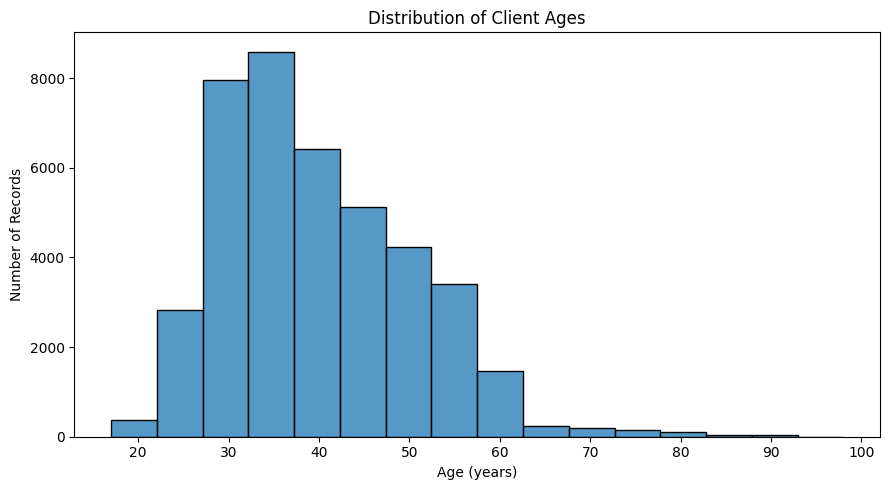

In [9]:
# Summarize client ages
display(df["age"].describe())

# Plot the distribution of client ages
plt.figure(figsize=(9, 5))
sns.histplot(data=df, x="age", binwidth=5)

plt.title("Distribution of Client Ages")
plt.xlabel("Age (years)")
plt.ylabel("Number of Records")
plt.tight_layout()
plt.show()

### Client Age Summary

Client ages range from 17 to 98 years. The mean age is approximately
40.02 years, and the median is 38 years. The middle 50% of ages fall
between 32 and 47 years. The standard deviation is approximately
10.42 years.

,count,percent
job,,
admin.,10422,25.30
blue-collar,9254,22.47
technician,6743,16.37
services,3969,9.64
management,2924,7.10
retired,1720,4.18
entrepreneur,1456,3.54
self-employed,1421,3.45
housemaid,1060,2.57


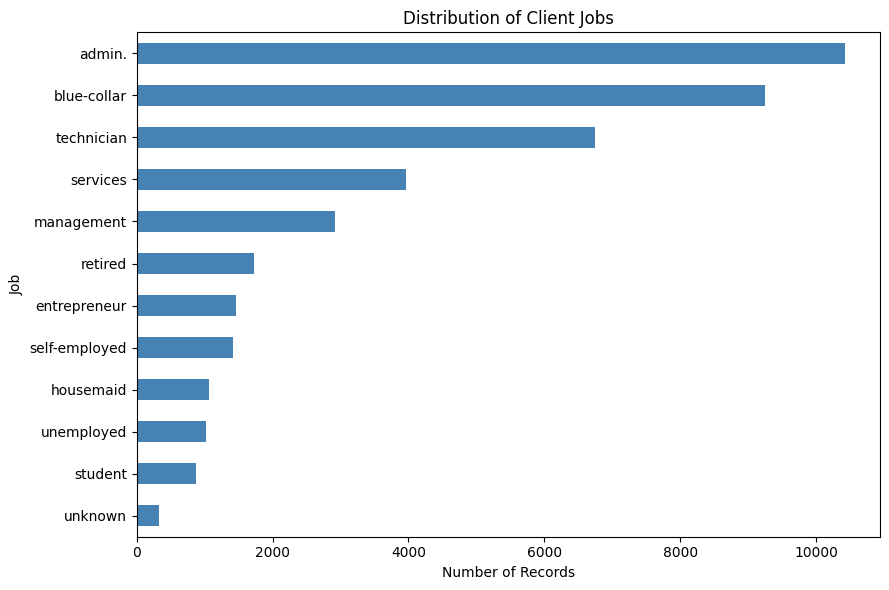

In [8]:
# Explore the distribution of client jobs
job_summary = df["job"].value_counts().to_frame("count")

job_summary["percent"] = (
    job_summary["count"] / len(df) * 100
).round(2)

display(job_summary)

# Plot the number of records by job
ax = job_summary["count"].sort_values().plot(
    kind="barh",
    figsize=(9, 6),
    color="steelblue"
)

ax.set_title("Distribution of Client Jobs")
ax.set_xlabel("Number of Records")
ax.set_ylabel("Job")

plt.tight_layout()
plt.show()

### Client Job Distribution

The most common job categories are administrative workers (25.30%),
blue-collar workers (22.47%), and technicians (16.37%). Together, they
account for approximately 64.14% of all records.

Students are the least represented known job category (2.12%).
Job information is unknown for 0.80% of records.

In [4]:
# Check the distribution of default status
default_summary = df["default"].value_counts().to_frame("count")
default_summary["percent"] = (
    default_summary["count"] / len(df) * 100
).round(2)

display(default_summary)

,count,percent
default,,
no,32588,79.12
unknown,8597,20.87
yes,3,0.01


In [3]:
# Check the distribution of housing loan status
housing_summary = df["housing"].value_counts().to_frame("count")
housing_summary["percent"] = (
    housing_summary["count"] / len(df) * 100
).round(2)

display(housing_summary)

,count,percent
housing,,
yes,21576,52.38
no,18622,45.21
unknown,990,2.40


In [7]:
# Check the distribution of loan status
loan_summary = df["loan"].value_counts().to_frame("count")
loan_summary["percent"] = (
    loan_summary["count"] / len(df) * 100
).round(2)

display(loan_summary)

,count,percent
loan,,
no,33950,82.43
yes,6248,15.17
unknown,990,2.40


In [5]:
# Check the distribution of y status
y_summary = df["y"].value_counts().to_frame("count")
y_summary["percent"] = (
    y_summary["count"] / len(df) * 100
).round(2)

display(y_summary)

,count,percent
y,,
no,36548,88.73
yes,4640,11.27


In [11]:
# Summarize the number of contacts per client
display(df["campaign"].describe())

# Count records for each number of contacts
campaign_summary = (
    df["campaign"]
    .value_counts()
    .head(5)
    .to_frame("count")
)

campaign_summary["percent"] = (
    campaign_summary["count"] / len(df) * 100
).round(2)

display(campaign_summary)

,campaign
count,41188.000000
mean,2.567593
std,2.770014
min,1.000000
25%,1.000000
50%,2.000000
75%,3.000000
max,56.000000


,count,percent
campaign,,
1,17642,42.83
2,10570,25.66
3,5341,12.97
4,2651,6.44
5,1599,3.88


### Campaign Distribution

Most records have a small number of contacts during the current campaign.
One contact is the most common (42.83%), and approximately 81.46% of
records have 1–3 contacts. The mean is 2.57 contacts, while the median
is 2. The maximum is 56, indicating a right-skewed distribution with
a small number of high contact counts.

,count,percent
poutcome,,
nonexistent,35563,86.34
failure,4252,10.32
success,1373,3.33


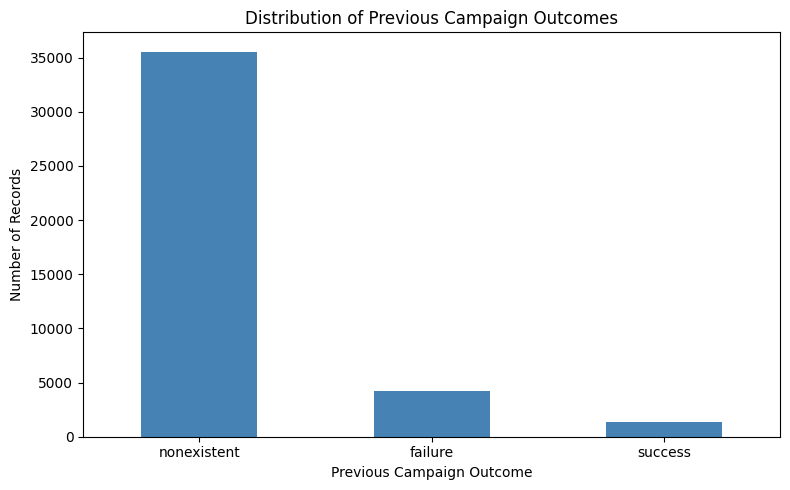

In [12]:
# Explore previous campaign outcomes
poutcome_summary = df["poutcome"].value_counts().to_frame("count")

poutcome_summary["percent"] = (
    poutcome_summary["count"] / len(df) * 100
).round(2)

display(poutcome_summary)

ax = poutcome_summary["count"].plot(
    kind="bar",
    figsize=(8, 5),
    color="steelblue",
    rot=0
)

ax.set_title("Distribution of Previous Campaign Outcomes")
ax.set_xlabel("Previous Campaign Outcome")
ax.set_ylabel("Number of Records")

plt.tight_layout()
plt.show()

### Previous Campaign Outcome Distribution

Most records have no previous campaign outcome (`nonexistent`, 86.34%).
Previous campaigns were recorded as failures for 10.32% of records
and successes for 3.33%.

In [14]:
# Check whether clients were previously contacted
previously_contacted = df["pdays"].ne(999)

pdays_summary = (
    previously_contacted.value_counts()
    .rename(index={True: "Previously contacted",
                   False: "Maybe not previously contacted"})
    .to_frame("count")
)

pdays_summary["percent"] = (
    pdays_summary["count"] / len(df) * 100
).round(2)

display(pdays_summary)

# Summarize actual intervals for previously contacted records
display(df.loc[previously_contacted, "pdays"].describe())

,count,percent
pdays,,
Maybe not previously contacted,39673,96.32
Previously contacted,1515,3.68


,pdays
count,1515.000000
mean,6.014521
std,3.824906
min,0.000000
25%,3.000000
50%,6.000000
75%,7.000000
max,27.000000


### Days Since Previous Contact

The special value 999 appears in 96.32% of `pdays` records and is
excluded from the numerical summary of contact intervals.

For the remaining 1,515 records (3.68%), the intervals range from
0 to 27 days. The mean is 6.01 days, and the median is 6 days.
The middle 50% of intervals fall between 3 and 7 days.